# Topological Photonic Crystals I — Unit Cells, Band Gaps and Edge States

All-dielectric photonic crystals can host topological edge states without magnetic
materials, by exploiting a crystal symmetry instead of time-reversal breaking:

- **Spin-Hall (Wu & Hu, *PRL* 114, 223901 (2015)).** A honeycomb lattice viewed as a
  triangular lattice of six-site clusters folds the Dirac cones of K and K′ onto Γ. Shrinking
  the clusters opens an ordinary gap (p-like bands below d-like ones at Γ); expanding them
  inverts the order. The C6 symmetry supplies a pseudo-time-reversal operator whose
  Kramers pairs (pseudospins) are the ±1 angular momenta of the field around a cluster.
- **Valley-Hall (Ma & Shvets 2016; He et al., *Nat. Commun.* 10, 872 (2019); Shalaev et al.,
  *Nat. Nanotechnol.* 14, 31 (2019)).** Keeping the honeycomb but making its two sublattice
  inclusions unequal breaks inversion symmetry; the Dirac points at K and K′ open with
  Berry curvature of opposite sign in the two valleys.

Each mechanism is shown in two complementary forms: **dielectric pillars in air (TM, Ez)**
and **air holes in a dielectric (TE, Hz)**, the form used in planar silicon photonics.

| crystal | inclusions | polarization | trivial / topological (or partners) |
|---|---|---|---|
| spin-Hall pillars | six Si rods, d = 0.24 a0, on a hexagon of edge R | TM | a0/R = 3.125 / 2.9 |
| spin-Hall holes | six triangular holes, side 0.3125 a0, vertex toward the centre | TE | a0/R = 3.125 / 2.9 |
| valley-Hall holes | inverted triangles, sides 0.433 a / 0.650 a | TE | VPC1 / VPC2 (sizes swapped) |
| valley-Hall pillars | Si rods, radii 0.187 a / 0.229 a | TM | VPC1 / VPC2 (radii swapped) |

The symmetric limits of both families are the same honeycomb (a = a0/√3, the spin-Hall hole
and rod sizes), so the four crystals are directly comparable. Valley sizes follow Shalaev
et al. (triangles) and Lan et al., *PRA* 103, L041502 (2021) (rods, 0.18 a / 0.22 a, here
rescaled to 0.187 a / 0.229 a so that their mean radius equals the symmetric honeycomb's
0.208 a = 0.12 a0).

**Model:** 2D, non-dispersive, silicon εd = 11.7 and air (the bulk index of the Wu–Hu paper,
not the toolkit's 2D effective index; see `src/pic_toolkit/meep_sim/topological_pc.py`).
Spin-Hall lengths in a0, valley-Hall lengths in a; frequencies in c/a0 and c/a.

**Kernel:** `mp` conda env, run from `topological/notebooks/`. The MPB data are produced by
`scripts/compute_bands.py` and cached in `data/bands/`. **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, plotting style, cached data.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon

import meep as mp
from pic_toolkit import style
from pic_toolkit.meep_sim import topological_pc as tp

style.apply_style()
mp.verbosity(0)
DATA = Path.cwd().parent / "data" / "bands"
SQ3 = np.sqrt(3)
FAMILY = {"spin_tm": ("trivial", "honeycomb", "topological"), "spin_te": ("trivial", "honeycomb", "topological"),
          "valley_te": ("symmetric", "vpc1", "vpc2"), "valley_tm": ("symmetric", "vpc1", "vpc2")}
TITLE = {"spin_tm": "spin-Hall pillars (TM)", "spin_te": "spin-Hall holes (TE)",
         "valley_te": "valley-Hall holes (TE)", "valley_tm": "valley-Hall pillars (TM)"}
UNIT = {"spin_tm": "a0", "spin_te": "a0", "valley_te": "a", "valley_tm": "a"}
print("valley TE sizes (VPC1: A, B):", np.round(tp.valley_sizes("valley_te", "vpc1"), 3),
      "  valley TM radii:", np.round(tp.valley_sizes("valley_tm", "vpc1"), 3))

valley TE sizes (VPC1: A, B): [0.433 0.65 ]   valley TM radii: [0.187 0.229]


## 1. Structures

The dielectric function as MPB sees it (`get_epsilon`, including sub-pixel smoothing) for
the two crystals of each pair, tiled over neighbouring cells. Spin-Hall cells are outlined
by their hexagonal Wigner–Seitz cell (one six-site cluster); valley-Hall cells by the
diamond-shaped primitive cell holding one A (lower) and one B (upper) inclusion.

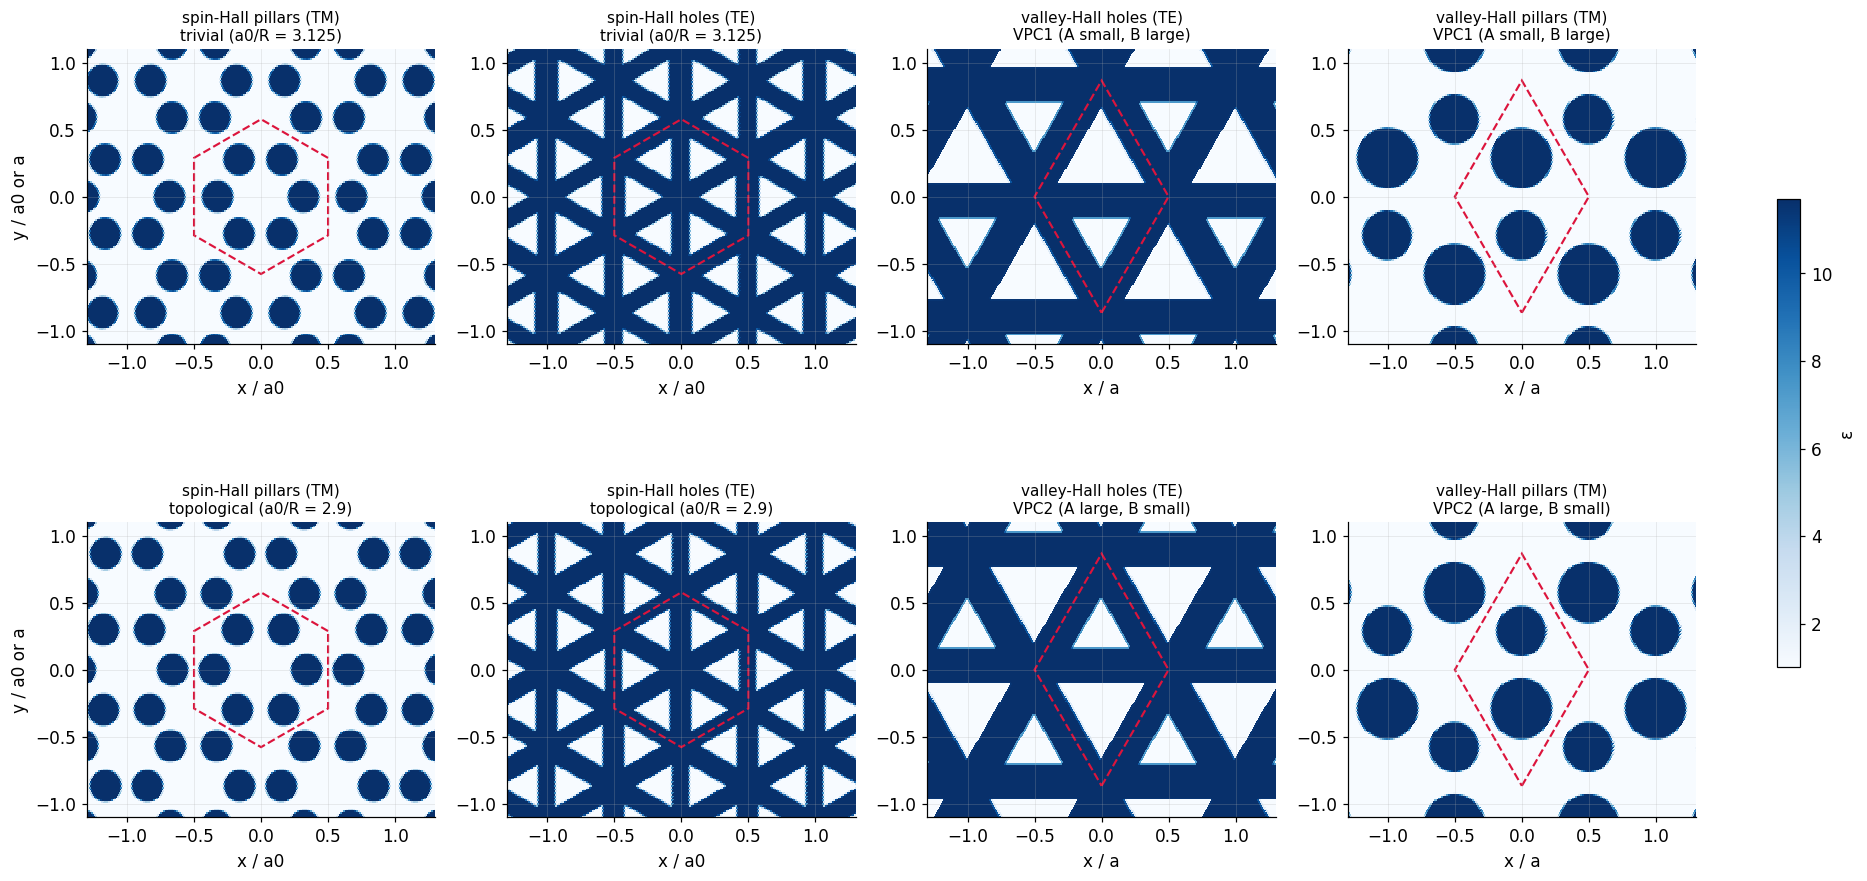

In [2]:
# Permittivity maps of the eight cells (resolution 64): trivial / topological for spin-Hall,
# VPC1 / VPC2 for valley-Hall.
ws_hex = np.array([[np.cos(t), np.sin(t)] for t in np.pi / 6 + np.arange(6) * np.pi / 3]) / SQ3
diamond = np.array([[0, -SQ3 / 2], [0.5, 0], [0, SQ3 / 2], [-0.5, 0]])
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6), layout="constrained")
for col, kind in enumerate(tp.KINDS):
    for row, var in enumerate(FAMILY[kind][::2] if kind.startswith("spin") else FAMILY[kind][1:]):
        e = tp.cell_epsilon(kind, var, resolution=64)
        ax = axes[row, col]
        for m in range(-3, 4):
            for n in range(-3, 4):
                X, Y = tp.cell_corner_grid(e.shape[0], m, n)
                ax.pcolormesh(X, Y, e, cmap=style.CMAP_PERMITTIVITY_BASELINE, vmin=1, vmax=tp.EPS_D,
                              shading="flat", rasterized=True)
        ax.add_patch(Polygon(ws_hex if kind.startswith("spin") else diamond, fill=False,
                             ec=style.COLOR_ANNOTATION, lw=1.4, ls="--"))
        ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
        lab = {"trivial": "trivial (a0/R = 3.125)", "topological": "topological (a0/R = 2.9)",
               "vpc1": "VPC1 (A small, B large)", "vpc2": "VPC2 (A large, B small)"}[var]
        ax.set_title(f"{TITLE[kind]}\n{lab}", fontsize=10)
        ax.set_xlabel(f"x / {UNIT[kind]}")
        if col == 0:
            ax.set_ylabel("y / a0 or a")
fig.colorbar(axes[0, 0].collections[0], ax=axes, shrink=0.5, label="ε")
fig.savefig(DATA.parent / "fig_structures.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Bulk band structures

TE or TM bands along Γ–M–K–Γ (K adjacent to M), 41 k-points per segment, resolution 48,
plotted as points. Shaded: complete band gaps.

For the spin-Hall crystals each point is coloured by the angular character of the field
(Ez for pillars, Hz for holes) on the ring of cluster sites: the share of p-like (m = ±1)
in the p + d weight. Points dominated by s or f character are black. At Γ the lower doublet
of the gap is p-like for the shrunken (trivial) cluster and d-like for the expanded
(topological) one: the band inversion. At a0/R = 3 the four bands meet at Γ (the folded
Dirac cones).

For the valley-Hall crystals the symmetric lattice has a Dirac point at K; the unequal
inclusions open a gap there, and the two inversion partners have identical bands.

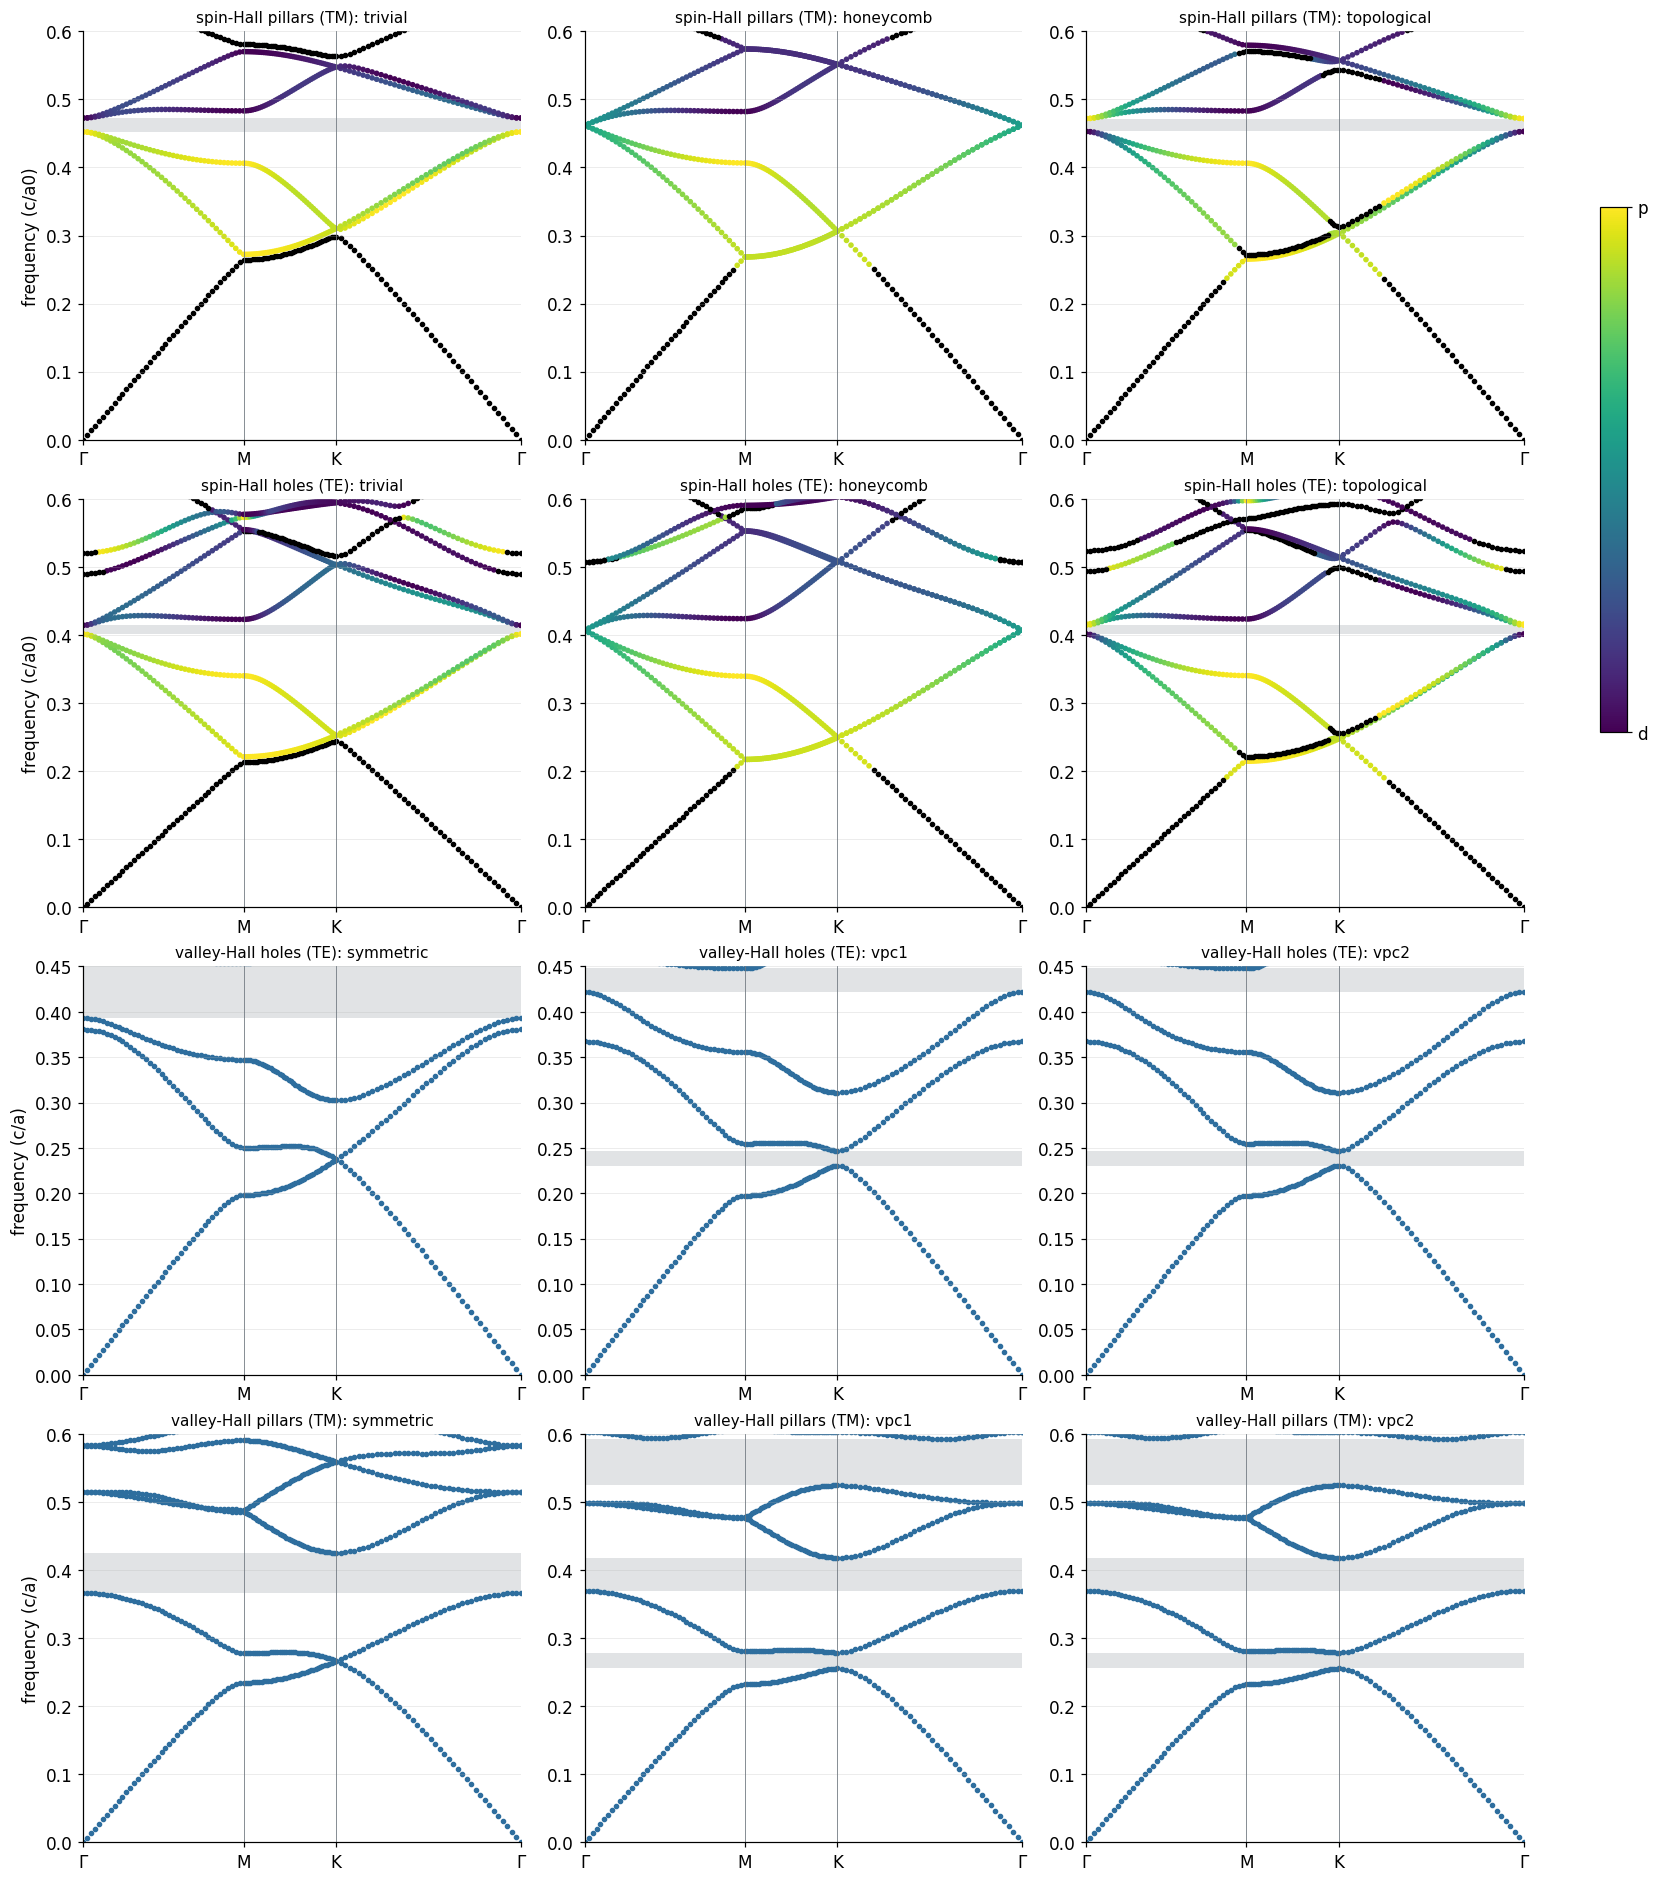

In [3]:
# Bulk bands, points, spin crystals coloured by p-fraction of p+d.
def load_bulk(kind, var):
    return dict(np.load(DATA / f"bulk_{kind}_{var}.npz"))

def plot_bulk(ax, kind, var, ylim):
    b = load_bulk(kind, var)
    f, d, t = b["freqs"], b["dist"], b["ticks"]
    for g in tp.complete_gaps(f, 2e-3):
        if ylim[0] < g["center"] < ylim[1]:
            ax.axhspan(g["lo"], g["hi"], color=style.COLOR_REFERENCE, alpha=0.2, lw=0)
    if "weights" in b:
        w = np.nan_to_num(b["weights"])
        pd = w[..., 1] + w[..., 2]
        pfrac = np.divide(w[..., 1], pd, out=np.zeros_like(pd), where=pd > 0)
        for n in range(f.shape[1]):
            dom = pd[:, n] > 0.5
            ax.scatter(d[dom], f[dom, n], c=pfrac[dom, n], cmap=style.CMAP_DENSITY, vmin=0, vmax=1, s=7)
            ax.scatter(d[~dom], f[~dom, n], c="k", s=7)
    else:
        for n in range(f.shape[1]):
            ax.scatter(d, f[:, n], color=style.COLOR_STEEL, s=7)
    ax.set_xticks(t, ["Γ", "M", "K", "Γ"]); ax.set_xlim(d[0], d[-1]); ax.set_ylim(*ylim)
    for x in t[1:-1]:
        ax.axvline(x, color=style.COLOR_REFERENCE, lw=0.5)

YLIM = {"spin_tm": (0, 0.6), "spin_te": (0, 0.6), "valley_te": (0, 0.45), "valley_tm": (0, 0.6)}
fig, axes = plt.subplots(4, 3, figsize=(15, 17), layout="constrained")
for r, kind in enumerate(tp.KINDS):
    for c, var in enumerate(FAMILY[kind]):
        plot_bulk(axes[r, c], kind, var, YLIM[kind])
        axes[r, c].set_title(f"{TITLE[kind]}: {var}", fontsize=10)
    axes[r, 0].set_ylabel(f"frequency (c/{UNIT[kind]})")
sm = plt.cm.ScalarMappable(cmap=style.CMAP_DENSITY); sm.set_array([])
cb = fig.colorbar(sm, ax=axes[:2, :], shrink=0.6, ticks=[0, 1]); cb.ax.set_yticklabels(["d", "p"])
fig.savefig(DATA.parent / "fig_bulk_bands.png", dpi=150, bbox_inches="tight")
plt.show()

**Band inversion at Γ.** A zoom on the spin-Hall gap near Γ (the M–Γ and Γ–K legs
next to Γ): the doublet below the gap is p-like (yellow) for the trivial cluster and d-like
(purple) for the topological one, and the order above the gap is reversed.

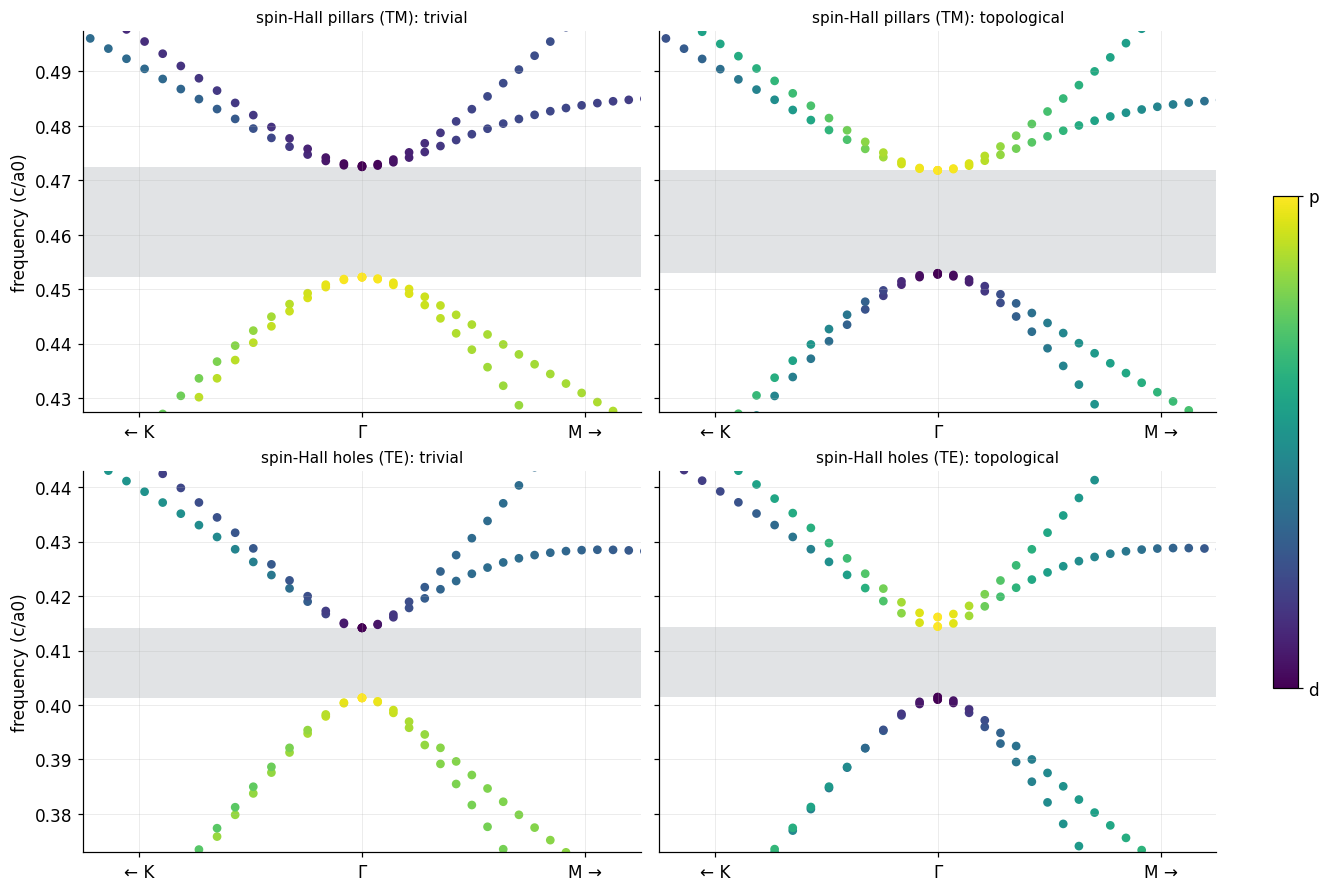

In [4]:
# Zoom around Gamma and the gap for the spin-Hall crystals, larger points.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="row", layout="constrained")
for r, kind in enumerate(("spin_tm", "spin_te")):
    for c, var in enumerate(("trivial", "topological")):
        ax = axes[r, c]
        b = load_bulk(kind, var)
        f, d, t = b["freqs"], b["dist"], b["ticks"]
        w = np.nan_to_num(b["weights"]); pd = w[..., 1] + w[..., 2]
        pfrac = np.divide(w[..., 1], pd, out=np.zeros_like(pd), where=pd > 0)
        # unfold the path so that Gamma sits at the centre: ... K - Gamma | Gamma - M ...
        x = np.concatenate([d[d >= t[2]] - d[-1], d[d <= t[1]]])
        idx = np.concatenate([np.where(d >= t[2])[0], np.where(d <= t[1])[0]])
        g = [x_ for x_ in tp.complete_gaps(f) if x_["below_band"] == 3][0]
        ax.axhspan(g["lo"], g["hi"], color=style.COLOR_REFERENCE, alpha=0.2, lw=0)
        for n in range(1, 6):
            ax.scatter(x, f[idx, n], c=pfrac[idx, n], cmap=style.CMAP_DENSITY, vmin=0, vmax=1, s=22)
        ax.set_xlim(-0.25, 0.25); ax.set_ylim(g["center"] - 0.035, g["center"] + 0.035)
        ax.set_xticks([-0.2, 0, 0.2], ["← K", "Γ", "M →"])
        ax.set_title(f"{TITLE[kind]}: {var}", fontsize=10)
    axes[r, 0].set_ylabel(f"frequency (c/{UNIT[kind]})")
sm = plt.cm.ScalarMappable(cmap=style.CMAP_DENSITY); sm.set_array([])
cb = fig.colorbar(sm, ax=axes, shrink=0.6, ticks=[0, 1]); cb.ax.set_yticklabels(["d", "p"])
fig.savefig(DATA.parent / "fig_band_inversion.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Gap table: the topological gap of each pair (between the p/d quadruplet for spin-Hall,
# bands 1|2 for valley-Hall), and the window shared by the two crystals of a pair.
GAP_BAND = {"spin_tm": 3, "spin_te": 3, "valley_te": 1, "valley_tm": 1}
gap_table = {}
print(f"{'crystal':>26} {'cell':>12} {'gap (c/unit)':>18} {'centre':>8} {'rel.':>7}")
for kind in tp.KINDS:
    pair = FAMILY[kind][::2] if kind.startswith("spin") else FAMILY[kind][1:]
    gs = []
    for var in pair:
        g = [x for x in tp.complete_gaps(load_bulk(kind, var)["freqs"]) if x["below_band"] == GAP_BAND[kind]][0]
        gs.append(g)
        print(f"{TITLE[kind]:>26} {var:>12} {g['lo']:.4f}-{g['hi']:.4f} {g['center']:>8.4f} {100 * g['width'] / g['center']:>6.2f}%")
    lo, hi = max(g["lo"] for g in gs), min(g["hi"] for g in gs)
    gap_table[kind] = (lo, hi)
    print(f"{'':>26} {'shared':>12} {lo:.4f}-{hi:.4f} {(lo + hi) / 2:>8.4f} {200 * (hi - lo) / (hi + lo):>6.2f}%")
g = gap_table["spin_tm"]
print(f"\nWu & Hu (d = 0.24 a0, a0 = 1 µm): gap 5.47 THz at 138.77 THz -> centre {138.77 / 299.792458:.4f}, "
      f"width {5.47 / 299.792458:.4f} c/a0; here (topological cell) see the table above")

                   crystal         cell       gap (c/unit)   centre    rel.
    spin-Hall pillars (TM)      trivial 0.4522-0.4725   0.4623   4.38%
    spin-Hall pillars (TM)  topological 0.4529-0.4718   0.4624   4.09%
                                 shared 0.4529-0.4718   0.4624   4.09%
      spin-Hall holes (TE)      trivial 0.4013-0.4142   0.4077   3.15%
      spin-Hall holes (TE)  topological 0.4014-0.4144   0.4079   3.18%
                                 shared 0.4014-0.4142   0.4078   3.12%
    valley-Hall holes (TE)         vpc1 0.2305-0.2466   0.2385   6.75%
    valley-Hall holes (TE)         vpc2 0.2305-0.2466   0.2385   6.75%
                                 shared 0.2305-0.2466   0.2385   6.75%
  valley-Hall pillars (TM)         vpc1 0.2554-0.2787   0.2671   8.71%
  valley-Hall pillars (TM)         vpc2 0.2554-0.2787   0.2671   8.71%
                                 shared 0.2554-0.2787   0.2671   8.71%

Wu & Hu (d = 0.24 a0, a0 = 1 µm): gap 5.47 THz at 138.77 THz -> centre 

## 3. Edge states at the domain wall

A **ribbon supercell** — one period along the wall, 8 + 8 rows across it, periodic — holds
the wall between the two crystals of a pair at y = 0 and, at the cell edge, the
wrap-around wall. Every band is evaluated on 51 values of kx and plotted as points,
coloured when its |Ez|² (TM) or |Hz|² (TE) is concentrated within one row height of the
walls (combined share > 0.28; bulk states stay below ≈ 0.25). In the spin-Hall ribbons the
two walls are mirror images, so their edge states are degenerate and MPB returns mixtures
of both (third colour); the two valley-Hall walls differ (large vs small inclusions facing)
and their states separate. Spin-Hall walls join the topological crystal (below) and the trivial one
(above); valley-Hall walls are bearded, with the large inclusions of VPC1 (above) and VPC2
(below) facing each other. Resolutions: 32/a0 (spin), 24/a (valley), as in the
domain-wall simulations of notebook 02. Shaded: the shared bulk gap of the pair.

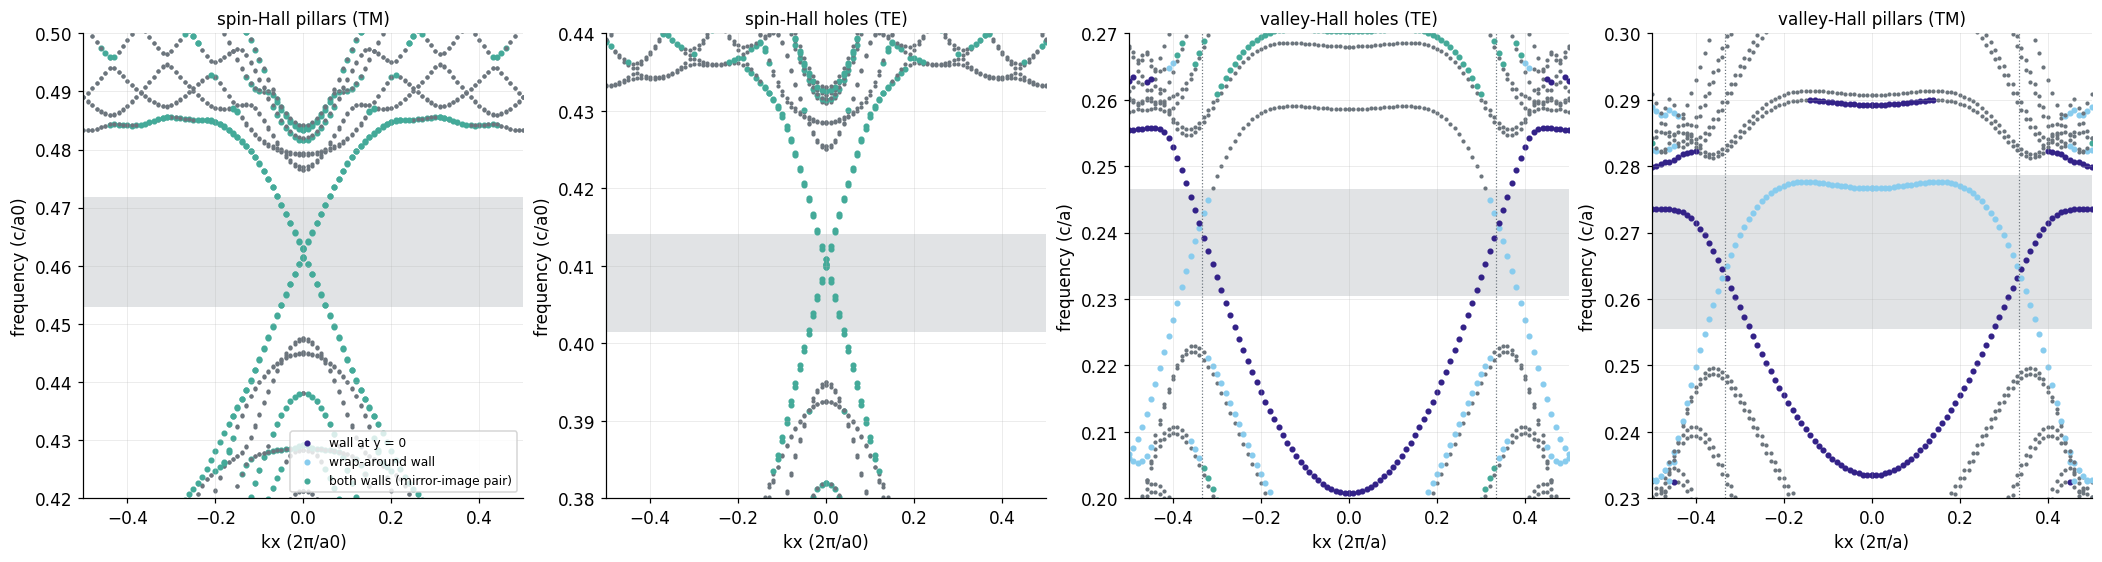

In [6]:
# Ribbon bands as points: gray = bulk; coloured = wall states, by which wall dominates.
EDGE = 0.28
fig, axes = plt.subplots(1, 4, figsize=(19, 5), layout="constrained")
YR = {"spin_tm": (0.42, 0.50), "spin_te": (0.38, 0.44), "valley_te": (0.20, 0.27), "valley_tm": (0.23, 0.30)}
for ax, kind in zip(axes, tp.KINDS):
    rb = dict(np.load(DATA / f"ribbon_{kind}.npz"))
    kx, f, loc = rb["kx"], rb["freqs"], rb["loc"]
    ax.axhspan(*gap_table[kind], color=style.COLOR_REFERENCE, alpha=0.2, lw=0)
    for sgn in (1, -1):
        for n in range(f.shape[1]):
            l0, l1 = loc[:, n, 0], loc[:, n, 1]
            edge = l0 + l1 > EDGE
            w1, w2 = edge & (l0 > 1.5 * l1), edge & (l1 > 1.5 * l0)
            both = edge & ~w1 & ~w2
            ax.scatter(sgn * kx[~edge], f[~edge, n], color=style.COLOR_REFERENCE, s=3)
            ax.scatter(sgn * kx[w1], f[w1, n], color=style.COLOR_CYCLE[0], s=9)
            ax.scatter(sgn * kx[w2], f[w2, n], color=style.COLOR_CYCLE[1], s=9)
            ax.scatter(sgn * kx[both], f[both, n], color=style.COLOR_CYCLE[2], s=9)
    if kind.startswith("valley"):
        for kk in (-1 / 3, 1 / 3):
            ax.axvline(kk, color=style.COLOR_REFERENCE, ls=":", lw=0.8)
    ax.set_xlim(-0.5, 0.5); ax.set_ylim(*YR[kind])
    ax.set_xlabel(f"kx (2π/{UNIT[kind]})"); ax.set_ylabel(f"frequency (c/{UNIT[kind]})")
    ax.set_title(TITLE[kind], fontsize=11)
axes[0].scatter([], [], color=style.COLOR_CYCLE[0], s=9, label="wall at y = 0")
axes[0].scatter([], [], color=style.COLOR_CYCLE[1], s=9, label="wrap-around wall")
axes[0].scatter([], [], color=style.COLOR_CYCLE[2], s=9, label="both walls (mirror-image pair)")
axes[0].legend(fontsize=8, loc="lower right")
fig.savefig(DATA.parent / "fig_edge_bands.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Edge states of the wall at y = 0 (spin-Hall: the degenerate pair of both walls) inside the
# shared gap: kx and frequency ranges, and the group velocity d f / d kx (units of c) of each
# branch from a straight-line fit over the middle half of the gap. Spin-Hall: the branches
# below and above the kx = 0 crossing; valley-Hall: the single branch near K.
for kind in tp.KINDS:
    rb = dict(np.load(DATA / f"ribbon_{kind}.npz"))
    kx, f, loc = rb["kx"], rb["freqs"], rb["loc"]
    lo, hi = gap_table[kind]
    l0, l1 = loc[..., 0], loc[..., 1]
    mine = (l0 + l1 > EDGE) & ((l0 > 1.5 * l1) | kind.startswith("spin"))
    k_, f_ = np.array([(kx[i], f[i, n]) for i in range(len(kx)) for n in range(f.shape[1])
                       if mine[i, n] and lo < f[i, n] < hi]).T
    q = (lo + 0.25 * (hi - lo), hi - 0.25 * (hi - lo))
    if kind.startswith("spin"):
        f0 = f_[k_ == k_.min()].mean()
        branches = {"lower": f_ < f0, "upper": f_ > f0}
    else:
        branches = {"K valley": np.ones_like(f_, bool)}
    vg = {}
    for name, sel in branches.items():
        s_ = sel & (f_ > q[0]) & (f_ < q[1])
        vg[name] = abs(np.polyfit(k_[s_], f_[s_], 1)[0]) if s_.sum() >= 3 else np.nan
    print(f"{TITLE[kind]:>26}: kx {k_.min():.2f}-{k_.max():.2f}, f {f_.min():.4f}-{f_.max():.4f}, |v_g| " +
          ", ".join(f"{n} {v:.2f} c" if np.isfinite(v) else f"{n} n/a (branch leaves the gap)" for n, v in vg.items()))
par = json.loads((DATA / "parity_valley_te_kx032.json").read_text())
edge = max(par, key=lambda r: r["wall_share"])
print(f"\nvalley-Hall holes, bearded wall: edge mode at kx = 0.32, f = {edge['f']:.4f}: "
      f"<Hz|M_y Hz>/<Hz|Hz> = {edge['mirror']:+.3f} (odd about the wall); "
      f"the wall is mirror-symmetric (mismatch {tp.geometry_mirror_check('valley_te'):.0e} a)")

    spin-Hall pillars (TM): kx 0.00-0.05, f 0.4532-0.4705, |v_g| lower 0.14 c, upper 0.14 c
      spin-Hall holes (TE): kx 0.00-0.04, f 0.4017-0.4126, |v_g| lower 0.21 c, upper n/a (branch leaves the gap)
    valley-Hall holes (TE): kx 0.29-0.36, f 0.2313-0.2454, |v_g| K valley 0.21 c
  valley-Hall pillars (TM): kx 0.28-0.50, f 0.2559-0.2735, |v_g| K valley 0.11 c

valley-Hall holes, bearded wall: edge mode at kx = 0.32, f = 0.2372: <Hz|M_y Hz>/<Hz|Hz> = -0.993 (odd about the wall); the wall is mirror-symmetric (mismatch 5e-07 a)


## 4. Summary

- **Spin-Hall (Γ).** Both the pillar (TM) and hole (TE) versions show the Wu–Hu picture:
  a fourfold degeneracy at Γ for the honeycomb, and a gap with p below d for the shrunken
  cluster and d below p for the expanded one. Pillars: 4.1 % at 0.462 c/a0 (Wu & Hu quote
  0.463 c/a0 for the same rods); holes: 3.1 % at 0.408 c/a0. The trivial and topological
  gaps overlap almost completely, as a domain wall needs.
- **Valley-Hall (K).** The symmetric honeycomb has a Dirac point at K; unequal inclusions
  open a gap there, identical for the two inversion partners: 6.8 % at 0.239 c/a (holes)
  and 8.7 % at 0.267 c/a (pillars), about twice the spin-Hall gaps.
- **Edge states.** Every wall carries edge states across the shared gap. The spin-Hall
  edge bands cross at kx = 0 (Γ) — the pseudospin partners — with a small anticrossing from
  the wall's broken C6 symmetry; the valley-Hall edge bands traverse the gap near the
  projected K point (kx ≈ 1/3), with group velocities ≈ 0.1–0.2 c.
- The bearded valley-Hall hole wall is mirror-symmetric about its line and its edge mode is
  odd; notebook 03 shows why this matters for feeding it from a strip waveguide.